# Reel Insights: Data Cleaning

This notebook prepares the movie industry datasets for analysis.

Project: Exploratory Data Analysis of the Global Movie Industry (TMDB).

import pandas as pd

print("Welcome to Reel Insights!")
print("Let's analyse our movie data.")


In [2]:
import pandas as pd

# Load the corrected movie dataset
movies = pd.read_csv("../data/movies_cleaned_corrected.csv")

# Convert release dates into date format
movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

# Create a separate copy for financial calculations
financial_movies = movies.copy()

# Treat zero values as unknown only for financial analysis
financial_movies["budget"] = financial_movies["budget"].replace(0, pd.NA)
financial_movies["revenue"] = financial_movies["revenue"].replace(0, pd.NA)

print("Movies loaded:", len(movies))
print(movies.head())

Movies loaded: 2503
   movie_id            title original_language release_date  runtime  \
0    157336     Interstellar                en   2014-11-05      169   
1     27205        Inception                en   2010-07-15      148   
2     24428     The Avengers                en   2012-04-25      143   
3       155  The Dark Knight                en   2008-07-16      152   
4     19995           Avatar                en   2009-12-16      162   

        budget       revenue  popularity  vote_average  vote_count    status  \
0  165000000.0  7.466067e+08     73.0452         8.484       40566  Released   
1  160000000.0  8.390306e+08     55.8497         8.400       39727  Released   
2  220000000.0  1.518816e+09     72.2515         8.062       38993  Released   
3  185000000.0  1.004558e+09     60.5510         8.534       36255  Released   
4  237000000.0  2.923706e+09     48.1996         7.610       34348  Released   

                                            overview  
0  The adve

## Data Cleaning and Relational Schema Preparation

This notebook demonstrates the data cleaning and preparation process for the Reel Insights project.

The project uses six related TMDB CSV datasets:

- `movies.csv` – main movie information
- `genres.csv` – genre reference information
- `movie_genres.csv` – links movies with genres
- `cast.csv` – movie cast information
- `crew.csv` – movie crew information
- `movie_keywords.csv` – keywords associated with movies

The main objectives of this notebook are to inspect the raw datasets, identify data quality issues, remove duplicate records, handle missing or invalid values, validate relationships between the tables, and prepare cleaned datasets for the SQLite relational database and subsequent analysis.

In [3]:
# Load the six RAW datasets

movies_raw = pd.read_csv("../data/movies.csv")
genres_raw = pd.read_csv("../data/genres.csv")
movie_genres_raw = pd.read_csv("../data/movie_genres.csv")
cast_raw = pd.read_csv("../data/cast.csv")
crew_raw = pd.read_csv("../data/crew.csv")
keywords_raw = pd.read_csv("../data/movie_keywords.csv")

print("Raw datasets loaded successfully!")
print("Movies:", movies_raw.shape)
print("Genres:", genres_raw.shape)
print("Movie Genres:", movie_genres_raw.shape)
print("Cast:", cast_raw.shape)
print("Crew:", crew_raw.shape)
print("Movie Keywords:", keywords_raw.shape)

Raw datasets loaded successfully!
Movies: (2509, 12)
Genres: (19, 2)
Movie Genres: (6888, 2)
Cast: (24917, 6)
Crew: (7297, 6)
Movie Keywords: (41701, 3)


In [4]:
# Check duplicate rows in each raw dataset

print("Duplicate rows in raw datasets:")
print("Movies:", movies_raw.duplicated().sum())
print("Genres:", genres_raw.duplicated().sum())
print("Movie Genres:", movie_genres_raw.duplicated().sum())
print("Cast:", cast_raw.duplicated().sum())
print("Crew:", crew_raw.duplicated().sum())
print("Movie Keywords:", keywords_raw.duplicated().sum())

Duplicate rows in raw datasets:
Movies: 6
Genres: 0
Movie Genres: 10
Cast: 15
Crew: 8
Movie Keywords: 20


In [5]:
# Check missing values in each raw dataset

raw_datasets = {
    "Movies": movies_raw,
    "Genres": genres_raw,
    "Movie Genres": movie_genres_raw,
    "Cast": cast_raw,
    "Crew": crew_raw,
    "Movie Keywords": keywords_raw
}

for name, dataset in raw_datasets.items():
    print(f"\n{name} - Missing Values:")
    print(dataset.isnull().sum())


Movies - Missing Values:
movie_id             0
title                0
original_language    0
release_date         0
runtime              0
budget               0
revenue              0
popularity           0
vote_average         0
vote_count           0
status               0
overview             0
dtype: int64

Genres - Missing Values:
genre_id      0
genre_name    0
dtype: int64

Movie Genres - Missing Values:
movie_id    0
genre_id    0
dtype: int64

Cast - Missing Values:
cast_row_id        0
movie_id           0
person_id          0
actor_name         0
character_name    11
cast_order         0
dtype: int64

Crew - Missing Values:
crew_row_id    0
movie_id       0
person_id      0
person_name    0
job            0
department     0
dtype: int64

Movie Keywords - Missing Values:
movie_id        0
keyword_id      0
keyword_name    0
dtype: int64


In [6]:
# Create cleaned copies and remove duplicate rows

movies_clean = movies_raw.drop_duplicates().copy()
genres_clean = genres_raw.drop_duplicates().copy()
movie_genres_clean = movie_genres_raw.drop_duplicates().copy()
cast_clean = cast_raw.drop_duplicates().copy()
crew_clean = crew_raw.drop_duplicates().copy()
keywords_clean = keywords_raw.drop_duplicates().copy()

print("Rows after removing duplicates:")
print("Movies:", len(movies_clean))
print("Genres:", len(genres_clean))
print("Movie Genres:", len(movie_genres_clean))
print("Cast:", len(cast_clean))
print("Crew:", len(crew_clean))
print("Movie Keywords:", len(keywords_clean))

Rows after removing duplicates:
Movies: 2503
Genres: 19
Movie Genres: 6878
Cast: 24902
Crew: 7289
Movie Keywords: 41681


In [7]:
# Handle missing character names in the cast dataset

cast_clean["character_name"] = (
    cast_clean["character_name"].fillna("Unknown")
)

print(
    "Missing character names after cleaning:",
    cast_clean["character_name"].isnull().sum()
)

Missing character names after cleaning: 0


In [8]:
# Validate relationships between the cleaned tables

unknown_movie_genres = (
    ~movie_genres_clean["movie_id"].isin(movies_clean["movie_id"])
).sum()

unknown_cast_movies = (
    ~cast_clean["movie_id"].isin(movies_clean["movie_id"])
).sum()

unknown_crew_movies = (
    ~crew_clean["movie_id"].isin(movies_clean["movie_id"])
).sum()

unknown_keyword_movies = (
    ~keywords_clean["movie_id"].isin(movies_clean["movie_id"])
).sum()

unknown_genres = (
    ~movie_genres_clean["genre_id"].isin(genres_clean["genre_id"])
).sum()

print("Relational integrity check:")
print("Unknown movie IDs in Movie Genres:", unknown_movie_genres)
print("Unknown movie IDs in Cast:", unknown_cast_movies)
print("Unknown movie IDs in Crew:", unknown_crew_movies)
print("Unknown movie IDs in Movie Keywords:", unknown_keyword_movies)
print("Unknown genre IDs in Movie Genres:", unknown_genres)

Relational integrity check:
Unknown movie IDs in Movie Genres: 0
Unknown movie IDs in Cast: 0
Unknown movie IDs in Crew: 0
Unknown movie IDs in Movie Keywords: 0
Unknown genre IDs in Movie Genres: 0


In [9]:
# Check that movie_id is unique in the Movies table

duplicate_movie_ids = movies_clean["movie_id"].duplicated().sum()

print("Duplicate movie IDs in Movies table:", duplicate_movie_ids)
print("Total movies:", len(movies_clean))
print("Unique movie IDs:", movies_clean["movie_id"].nunique())

Duplicate movie IDs in Movies table: 0
Total movies: 2503
Unique movie IDs: 2503


## Relational Schema

The cleaned datasets form a relational structure centred around the `movies` table.

- **movies**: `movie_id` acts as the unique identifier for each movie.
- **genres**: `genre_id` identifies each genre.
- **movie_genres**: links movies and genres using `movie_id` and `genre_id`, allowing a movie to belong to multiple genres.
- **cast**: links cast members to movies through `movie_id`.
- **crew**: links crew members to movies through `movie_id`.
- **movie_keywords**: links descriptive keywords to movies through `movie_id`.

The relational integrity checks confirmed that all referenced movie IDs and genre IDs have matching records in their parent tables. No orphaned movie or genre references were found in the cleaned data.

In [140]:

print("Number of movies:", movies.shape[0])
print("Number of columns:", movies.shape[1])


Number of movies: 2503
Number of columns: 12


In [141]:

print(movies.columns.tolist())


['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview']


In [142]:

print(movies.isnull().sum())


movie_id             0
title                0
original_language    0
release_date         0
runtime              0
budget               0
revenue              0
popularity           0
vote_average         0
vote_count           0
status               0
overview             0
dtype: int64


In [143]:

print("Duplicate movie rows:", movies.duplicated().sum())


Duplicate movie rows: 0


In [144]:

print(movies.dtypes)

movie_id                      int64
title                           str
original_language               str
release_date         datetime64[us]
runtime                       int64
budget                      float64
revenue                     float64
popularity                  float64
vote_average                float64
vote_count                    int64
status                          str
overview                        str
dtype: object


In [145]:

movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

print(movies["release_date"].dtype)


datetime64[us]


In [146]:

print("Missing release dates:", movies["release_date"].isnull().sum())

Missing release dates: 0


In [147]:

print("Earliest release date:", movies["release_date"].min())
print("Latest release date:", movies["release_date"].max())


Earliest release date: 1921-01-21 00:00:00
Latest release date: 2026-06-10 00:00:00


In [148]:

average_rating = movies["vote_average"].mean()

print("Average movie rating:", round(average_rating, 2))


Average movie rating: 6.94


In [149]:

highest_rating = movies["vote_average"].max()

top_rated_movies = movies[
    movies["vote_average"] == highest_rating
]

print("Highest rating:", highest_rating)
print(top_rated_movies[["title", "vote_average"]])

Highest rating: 8.727
                      title  vote_average
8  The Shawshank Redemption         8.727


In [150]:

highest_popularity = movies["popularity"].max()

popular_movies = movies[
    movies["popularity"] == highest_popularity
]

print("Highest popularity score:", highest_popularity)
print(popular_movies[["title", "popularity"]])


Highest popularity score: 438.4757
                      title  popularity
46  Spider-Man: No Way Home    438.4757


In [151]:

longest_runtime = movies["runtime"].max()

longest_movies = movies[
    movies["runtime"] == longest_runtime
]

print("Longest runtime in minutes:", longest_runtime)
print(longest_movies[["title", "runtime"]])


Longest runtime in minutes: 242
                            title  runtime
324  Zack Snyder's Justice League      242


In [152]:
average_budget = financial_movies["budget"].mean()
print("Average movie budget: $", round(average_budget, 2))

average_revenue = financial_movies["revenue"].mean()
print("Average movie revenue: $", round(average_revenue, 2))

Average movie budget: $ 60816431.27
Average movie revenue: $ 223278963.3


In [153]:
# Keep only movies with known budget and revenue
valid_movies = financial_movies.dropna(
    subset=["budget", "revenue"]
).copy()

# Calculate profit
valid_movies["profit"] = (
    valid_movies["revenue"] - valid_movies["budget"]
)

print("Movies with known budget and revenue:", len(valid_movies))
print("Average movie profit: $", round(valid_movies["profit"].mean(), 2))

Movies with known budget and revenue: 2370
Average movie profit: $ 164891397.04


In [154]:
# Use movies with a known, positive budget
roi_movies = valid_movies[
    valid_movies["budget"] > 0
].copy()

# Calculate ROI as a percentage
roi_movies["ROI"] = (
    (roi_movies["revenue"] - roi_movies["budget"])
    / roi_movies["budget"]
) * 100

print(
    roi_movies[
        ["title", "budget", "revenue", "profit", "ROI"]
    ].head()
)

             title       budget       revenue        profit          ROI
0     Interstellar  165000000.0   746606706.0   581606706.0   352.488913
1        Inception  160000000.0   839030630.0   679030630.0   424.394144
2     The Avengers  220000000.0  1518815515.0  1298815515.0   590.370689
3  The Dark Knight  185000000.0  1004558444.0   819558444.0   443.004564
4           Avatar  237000000.0  2923706026.0  2686706026.0  1133.631235


In [155]:
top_roi = roi_movies[
    roi_movies["budget"] >= 1_000_000
].sort_values(
    by="ROI",
    ascending=False
).head(15)

print(
    top_roi[
        ["title", "budget", "revenue", "profit", "ROI"]
    ].to_string(index=False)
)

                          title      budget      revenue       profit           ROI
       Dragon Ball Super: Broly   1000000.0  125002821.0  124002821.0    12400.2821
Snow White and the Seven Dwarfs   1488423.0  184925486.0  183437063.0  12324.256142
  The Rocky Horror Picture Show   1400000.0  171181400.0  169781400.0  12127.242857
                          Rocky   1000000.0  117253345.0  116253345.0    11625.3345
             Gone with the Wind   4000000.0  402352579.0  398352579.0   9958.814475
                The Jungle Book   4000000.0  378000000.0  374000000.0        9350.0
                     Cinderella   2900000.0  263600000.0  260700000.0   8989.655172
                            Saw   1200000.0  104045735.0  102845735.0   8570.477917
 One Hundred and One Dalmatians   3600000.0  303000000.0  299400000.0   8316.666667
     E.T. the Extra-Terrestrial  10500000.0  797307407.0  786807407.0   7493.403876
       My Big Fat Greek Wedding   5000000.0  368744044.0  363744044.0    727

In [156]:
top_roi_display = top_roi[
    ["title", "budget", "revenue", "ROI"]
].copy()

top_roi_display["ROI"] = top_roi_display["ROI"].round(2)

print(top_roi_display.to_string(index=False))

                          title      budget      revenue       ROI
       Dragon Ball Super: Broly   1000000.0  125002821.0  12400.28
Snow White and the Seven Dwarfs   1488423.0  184925486.0  12324.26
  The Rocky Horror Picture Show   1400000.0  171181400.0  12127.24
                          Rocky   1000000.0  117253345.0  11625.33
             Gone with the Wind   4000000.0  402352579.0   9958.81
                The Jungle Book   4000000.0  378000000.0    9350.0
                     Cinderella   2900000.0  263600000.0   8989.66
                            Saw   1200000.0  104045735.0   8570.48
 One Hundred and One Dalmatians   3600000.0  303000000.0   8316.67
     E.T. the Extra-Terrestrial  10500000.0  797307407.0    7493.4
       My Big Fat Greek Wedding   5000000.0  368744044.0   7274.88
                      Star Wars  11000000.0  775398007.0   6949.07
                           Jaws   7000000.0  470653000.0   6623.61
                      Insidious   1500000.0  100106454.0   657

In [157]:
# Extract the release year
movies["release_year"] = movies["release_date"].dt.year

# Count movies released each year
movies_per_year = (
    movies["release_year"]
    .value_counts()
    .sort_index()
)

print("Number of years in the dataset:", len(movies_per_year))
print("\nMovies released per year:")
print(movies_per_year.tail(15))

print(
    "\nYear with the most movie releases:",
    movies_per_year.idxmax()
)

print(
    "Number of movies released that year:",
    movies_per_year.max()
)

Number of years in the dataset: 89

Movies released per year:
release_year
2012     82
2013    110
2014    105
2015     97
2016    121
2017    109
2018    102
2019    100
2020     52
2021     67
2022     65
2023     62
2024     43
2025     26
2026      8
Name: count, dtype: int64

Year with the most movie releases: 2016
Number of movies released that year: 121


In [158]:
genres = pd.read_csv("../data/genres_cleaned.csv")
movie_genres = pd.read_csv("../data/movie_genres_cleaned.csv")

genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_counts = genre_data["genre_name"].value_counts()

print("Number of movies linked to each genre:")
print(genre_counts)

Number of movies linked to each genre:
genre_name
Drama              937
Action             808
Comedy             762
Adventure          674
Thriller           673
Science Fiction    463
Fantasy            396
Crime              387
Romance            349
Family             344
Horror             339
Animation          246
Mystery            216
History            112
War                 85
Music               49
Western             33
TV Movie             4
Documentary          1
Name: count, dtype: int64


In [159]:
genre_ratings = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_ratings = genre_ratings.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id",
    how="left"
)

average_rating_by_genre = (
    genre_ratings.groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)

print(average_rating_by_genre.round(2))

genre_name
War                7.36
History            7.34
Music              7.32
Documentary        7.31
Drama              7.25
Animation          7.20
Western            7.13
Romance            7.03
TV Movie           7.01
Crime              7.01
Family             6.94
Mystery            6.88
Thriller           6.86
Adventure          6.83
Fantasy            6.83
Science Fiction    6.81
Comedy             6.81
Action             6.73
Horror             6.62
Name: vote_average, dtype: float64


In [160]:
cast = pd.read_csv("../data/cast_cleaned.csv")

top_actors = cast["actor_name"].value_counts().head(10)

print("Top 10 actors by movie appearances:")
print(top_actors)

Top 10 actors by movie appearances:
actor_name
Samuel L. Jackson     39
Brad Pitt             38
Robert De Niro        38
Johnny Depp           37
Tom Hanks             33
Scarlett Johansson    32
Willem Dafoe          32
Mark Wahlberg         32
Morgan Freeman        31
Tom Cruise            31
Name: count, dtype: int64


In [161]:
crew = pd.read_csv("../data/crew_cleaned.csv")

directors = crew[crew["job"] == "Director"]

top_directors = (
    directors["person_name"]
    .value_counts()
    .head(10)
)

print("Top 10 directors by movie count:")
print(top_directors)

Top 10 directors by movie count:
person_name
Steven Spielberg      27
Ridley Scott          19
Tim Burton            19
Martin Scorsese       16
Robert Zemeckis       15
Michael Bay           15
Clint Eastwood        14
M. Night Shyamalan    13
Robert Rodriguez      13
Antoine Fuqua         12
Name: count, dtype: int64


In [162]:
keywords = pd.read_csv("../data/movie_keywords_cleaned.csv")

top_keywords = (
    keywords["keyword_name"]
    .value_counts()
    .head(10)
)

print("Top 10 most common movie keywords:")
print(top_keywords)

Top 10 most common movie keywords:
keyword_name
based on novel or book    449
sequel                    416
duringcreditsstinger      296
aftercreditsstinger       242
murder                    176
based on true story       166
new york city             161
villain                   160
3d animation              155
based on comic            154
Name: count, dtype: int64


In [163]:
print("Shortest movie runtime:", movies["runtime"].min(), "minutes")
print("Longest movie runtime:", movies["runtime"].max(), "minutes")
print("Average movie runtime:", round(movies["runtime"].mean(), 2), "minutes")

Shortest movie runtime: 45 minutes
Longest movie runtime: 242 minutes
Average movie runtime: 114.41 minutes


In [164]:
print("Movies shorter than 60 minutes:")

print(
    movies.loc[
        movies["runtime"] < 60,
        ["title", "runtime"]
    ]
    .head(10)
    .to_string(index=False)
)

Movies shorter than 60 minutes:
                                      title  runtime
The Guardians of the Galaxy Holiday Special       45
                        The Garden of Words       46


In [165]:
print("Movies longer than 180 minutes:")

print(
    movies.loc[
        movies["runtime"] > 180,
        ["title", "runtime"]
    ]
    .sort_values("runtime", ascending=False)
    .head(10)
    .to_string(index=False)
)

Movies longer than 180 minutes:
                                        title  runtime
                 Zack Snyder's Justice League      242
                           Gone with the Wind      238
                  Once Upon a Time in America      229
                           Lawrence of Arabia      228
                                      Ben-Hur      212
                                 The Irishman      209
                                Seven Samurai      207
                   Killers of the Flower Moon      206
                        The Godfather Part II      202
The Lord of the Rings: The Return of the King      201


In [166]:
duplicate_titles = movies[
    movies.duplicated(subset=["title"], keep=False)
].sort_values("title")

print("Number of rows with repeated titles:", len(duplicate_titles))

print(
    duplicate_titles[["movie_id", "title", "release_date"]]
    .head(20)
    .to_string(index=False)
)

Number of rows with repeated titles: 100
 movie_id                     title release_date
      377 A Nightmare on Elm Street   1984-11-09
    23437 A Nightmare on Elm Street   2010-04-30
      812                   Aladdin   1992-11-25
   420817                   Aladdin   2019-05-22
    12155       Alice in Wonderland   2010-03-03
    12092       Alice in Wonderland   1951-08-09
   321612      Beauty and the Beast   2017-03-16
    10020      Beauty and the Beast   1991-10-22
   133805                    Carrie   2013-10-16
     7340                    Carrie   1976-11-03
     4327          Charlie's Angels   2000-11-02
   458897          Charlie's Angels   2019-11-14
   150689                Cinderella   2015-03-06
    11224                Cinderella   1950-02-22
    35056                Date Night   2010-04-08
  1368167                Date Night   1995-04-08
      924          Dawn of the Dead   2004-03-19
      923          Dawn of the Dead   1978-09-02
    11360                   

In [167]:
print("Missing values in each column:")

print(movies.isnull().sum())

Missing values in each column:
movie_id             0
title                0
original_language    0
release_date         0
runtime              0
budget               0
revenue              0
popularity           0
vote_average         0
vote_count           0
status               0
overview             0
release_year         0
dtype: int64


In [168]:
print("Movies with zero budget:", (movies["budget"] == 0).sum())

print("Movies with zero revenue:", (movies["revenue"] == 0).sum())

Movies with zero budget: 90
Movies with zero revenue: 102


In [169]:
print("Movie status counts:")

print(movies["status"].value_counts())

Movie status counts:
status
Released    2503
Name: count, dtype: int64


In [170]:
print("Top 10 original languages:")

print(
    movies["original_language"]
    .value_counts()
    .head(10)
)

Top 10 original languages:
original_language
en    2363
ja      34
fr      25
it      19
es      15
de      11
ko       9
cn       6
sv       4
pt       2
Name: count, dtype: int64


In [171]:
top_languages = movies["original_language"].value_counts().head(5).index

average_runtime_language = (
    movies[movies["original_language"].isin(top_languages)]
    .groupby("original_language")["runtime"]
    .mean()
    .sort_values(ascending=False)
)

print("Average runtime by language (minutes):")
print(average_runtime_language.round(2))

Average runtime by language (minutes):
original_language
it    121.89
es    116.07
en    114.33
fr    112.76
ja    107.94
Name: runtime, dtype: float64


<Axes: title={'center': 'Average Movie Runtime by Original Language'}, xlabel='Original Language', ylabel='Average Runtime (Minutes)'>

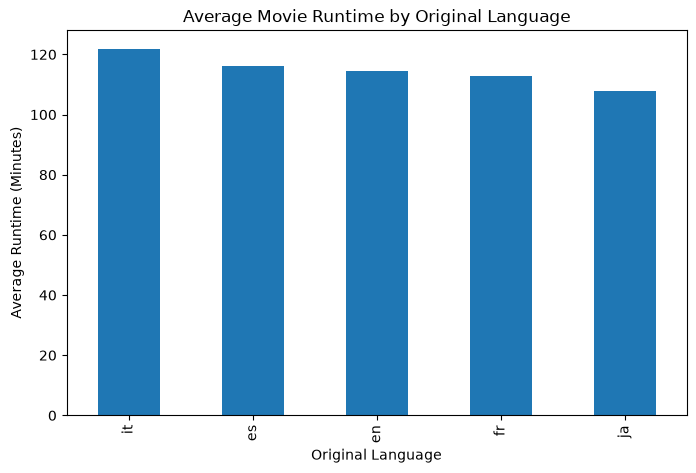

In [172]:
average_runtime_language.plot(
    kind="bar",
    title="Average Movie Runtime by Original Language",
    xlabel="Original Language",
    ylabel="Average Runtime (Minutes)",
    figsize=(8, 5)
)

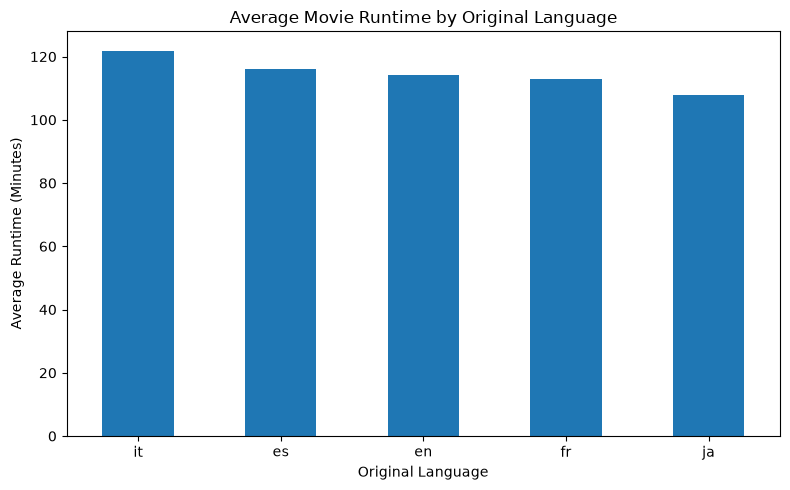

In [173]:
import matplotlib.pyplot as plt

average_runtime_language.plot(
    kind="bar",
    title="Average Movie Runtime by Original Language",
    xlabel="Original Language",
    ylabel="Average Runtime (Minutes)",
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [174]:
average_popularity_language = (
    movies.groupby("original_language")["popularity"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 languages by average movie popularity:")

print(average_popularity_language.head(10).round(2))

Top 10 languages by average movie popularity:
original_language
lv    23.52
sr    18.92
ko    17.50
hi    14.52
pt    13.90
en    13.84
ru    13.79
ja    11.81
zh    11.08
es    11.02
Name: popularity, dtype: float64


In [175]:
top_popular_languages = average_popularity_language.head(10).index

language_counts = (
    movies[movies["original_language"].isin(top_popular_languages)]
    ["original_language"]
    .value_counts()
)

print("Number of movies in each of the top 10 languages:")
print(language_counts)

Number of movies in each of the top 10 languages:
original_language
en    2363
ja      34
es      15
ko       9
pt       2
hi       2
zh       2
lv       1
ru       1
sr       1
Name: count, dtype: int64


In [176]:
language_summary = (
    movies.groupby("original_language")
    .agg(
        movie_count=("movie_id", "count"),
        average_popularity=("popularity", "mean")
    )
)

language_summary = language_summary[
    language_summary["movie_count"] >= 10
].sort_values("average_popularity", ascending=False)

print("Languages with at least 10 movies:")
print(language_summary.round(2))

Languages with at least 10 movies:
                   movie_count  average_popularity
original_language                                 
en                        2363               13.84
ja                          34               11.81
es                          15               11.02
fr                          25               10.69
it                          19                9.75
de                          11                8.44


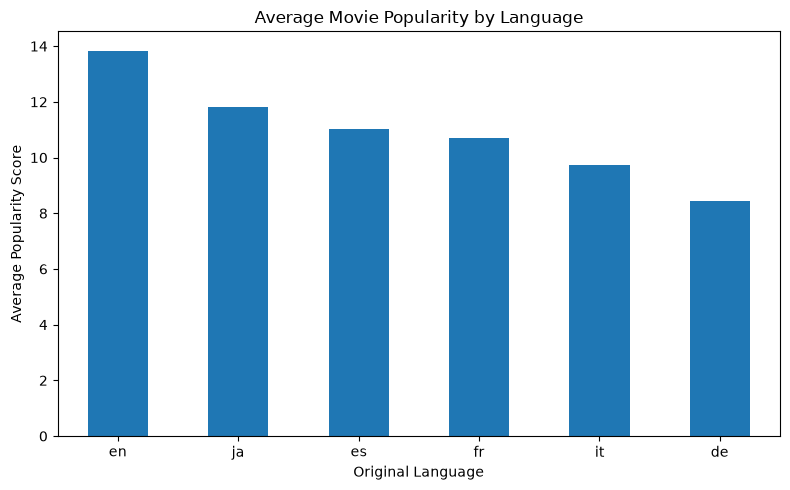

In [177]:
language_summary["average_popularity"].plot(
    kind="bar",
    title="Average Movie Popularity by Language",
    xlabel="Original Language",
    ylabel="Average Popularity Score",
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [178]:
highly_rated_movies = movies[
    movies["vote_count"] >= 1000
].sort_values(
    "vote_average",
    ascending=False
)

print("Top 10 highly rated movies with at least 1,000 votes:")

print(
    highly_rated_movies[
        ["title", "vote_average", "vote_count"]
    ].head(10).to_string(index=False)
)

Top 10 highly rated movies with at least 1,000 votes:
                      title  vote_average  vote_count
   The Shawshank Redemption         8.727       30915
                    Michael         8.696        3846
              The Godfather         8.686       23255
          Project Hail Mary         8.659        6750
           Schindler's List         8.570       17680
      The Godfather Part II         8.570       14116
               12 Angry Men         8.566       10192
            The Dark Knight         8.534       36255
              Spirited Away         8.533       18619
Dilwale Dulhania Le Jayenge         8.507        4607


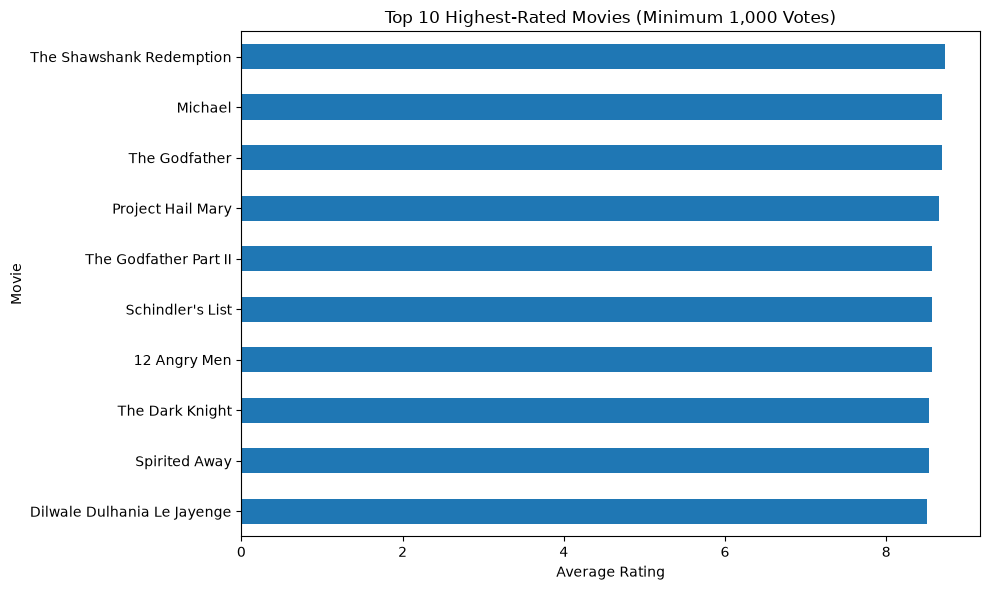

In [179]:
top_10_rated = highly_rated_movies.head(10).sort_values(
    "vote_average"
)

top_10_rated.plot(
    x="title",
    y="vote_average",
    kind="barh",
    title="Top 10 Highest-Rated Movies (Minimum 1,000 Votes)",
    xlabel="Average Rating",
    ylabel="Movie",
    legend=False,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [180]:
most_voted_movies = movies.sort_values(
    "vote_count",
    ascending=False
).head(10)

print("Top 10 movies by number of votes:")

print(
    most_voted_movies[
        ["title", "vote_count", "vote_average"]
    ].to_string(index=False)
)

Top 10 movies by number of votes:
                   title  vote_count  vote_average
            Interstellar       40566         8.484
               Inception       39727         8.400
            The Avengers       38993         8.062
         The Dark Knight       36255         8.534
                  Avatar       34348         7.610
                Deadpool       33003         7.625
              Fight Club       32496         8.438
  Avengers: Infinity War       32435         8.240
The Shawshank Redemption       30915         8.727
            Pulp Fiction       30542         8.482


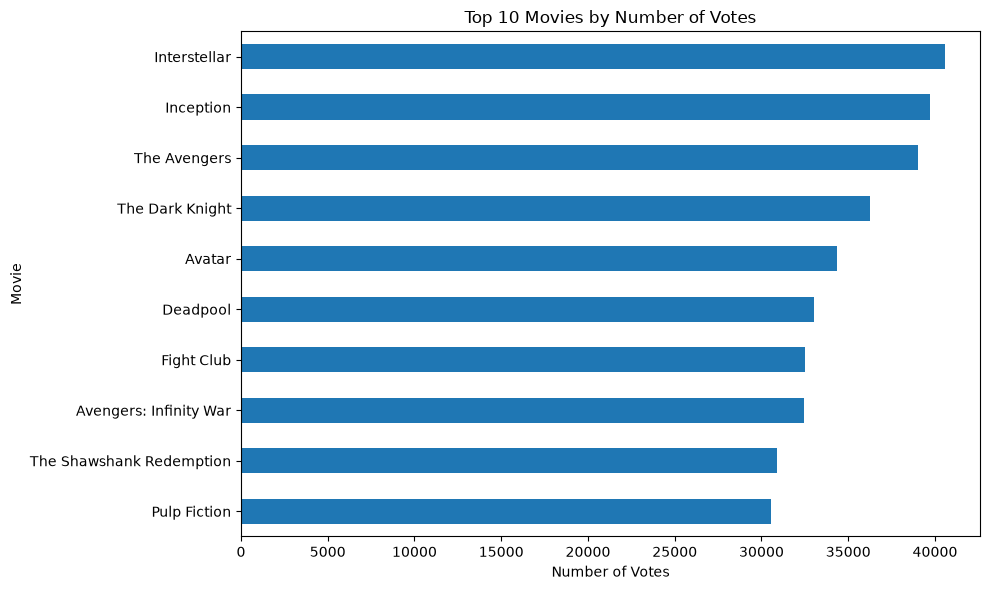

In [181]:
most_voted_movies_sorted = most_voted_movies.sort_values(
    "vote_count"
)

most_voted_movies_sorted.plot(
    x="title",
    y="vote_count",
    kind="barh",
    title="Top 10 Movies by Number of Votes",
    xlabel="Number of Votes",
    ylabel="Movie",
    legend=False,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [182]:
valid_movies = financial_movies.dropna(
    subset=["budget", "revenue"]
).copy()

valid_movies["profit"] = (
    valid_movies["revenue"] - valid_movies["budget"]
)

top_profit_movies = valid_movies.sort_values(
    "profit",
    ascending=False
).head(10)

print("Top 10 most profitable movies:")

print(
    top_profit_movies[
        ["title", "budget", "revenue", "profit"]
    ].to_string(index=False)
)

Top 10 most profitable movies:
                       title       budget       revenue        profit
                      Avatar  237000000.0  2923706026.0  2686706026.0
           Avengers: Endgame  356000000.0  2799439100.0  2443439100.0
                     Titanic  200000000.0  2264162353.0  2064162353.0
    Avatar: The Way of Water  460000000.0  2334484620.0  1874484620.0
Star Wars: The Force Awakens  245000000.0  2068223624.0  1823223624.0
      Avengers: Infinity War  300000000.0  2052415039.0  1752415039.0
     Spider-Man: No Way Home  200000000.0  1921206586.0  1721206586.0
                  Zootopia 2  150000000.0  1868208796.0  1718208796.0
              Jurassic World  150000000.0  1671537444.0  1521537444.0
                Inside Out 2  200000000.0  1698863816.0  1498863816.0


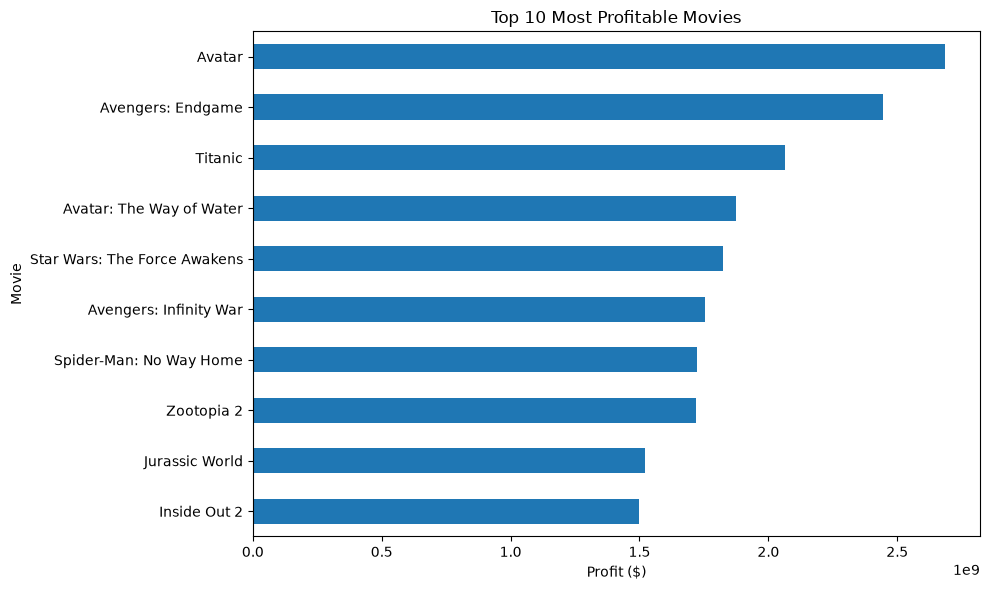

In [183]:
top_profit_sorted = top_profit_movies.sort_values("profit")

top_profit_sorted.plot(
    x="title",
    y="profit",
    kind="barh",
    title="Top 10 Most Profitable Movies",
    xlabel="Profit ($)",
    ylabel="Movie",
    legend=False,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [184]:
roi_movies = valid_movies[
    valid_movies["budget"] > 0
].copy()

roi_movies["ROI"] = (
    (roi_movies["revenue"] - roi_movies["budget"])
    / roi_movies["budget"]
) * 100

top_roi = roi_movies.sort_values(
    "ROI",
    ascending=False
).head(10)

print("Top 10 movies by ROI:")

print(
    top_roi[
        ["title", "budget", "revenue", "ROI"]
    ].to_string(index=False)
)

Top 10 movies by ROI:
                          title     budget      revenue             ROI
            Paranormal Activity    15000.0  193355800.0  1288938.666667
        The Blair Witch Project    60000.0  248639099.0   414298.498333
                      Obsession   750000.0  474895195.0    63219.359333
                          Bambi   858000.0  267447150.0    31070.996503
                        Mad Max   350000.0  100000000.0    28471.428571
       Night of the Living Dead   114000.0   30236452.0    26423.203509
   The Texas Chain Saw Massacre   140000.0   30922680.0    21987.628571
                      Halloween   325000.0   70260597.0    21518.645231
       Dragon Ball Super: Broly  1000000.0  125002821.0      12400.2821
Snow White and the Seven Dwarfs  1488423.0  184925486.0    12324.256142


In [185]:
top_roi_display = top_roi[
    ["title", "budget", "revenue", "ROI"]
].copy()

top_roi_display["ROI"] = top_roi_display["ROI"].round(2)

print("Top 10 movies by ROI (%):")
print(top_roi_display.to_string(index=False))

Top 10 movies by ROI (%):
                          title     budget      revenue         ROI
            Paranormal Activity    15000.0  193355800.0  1288938.67
        The Blair Witch Project    60000.0  248639099.0    414298.5
                      Obsession   750000.0  474895195.0    63219.36
                          Bambi   858000.0  267447150.0     31071.0
                        Mad Max   350000.0  100000000.0    28471.43
       Night of the Living Dead   114000.0   30236452.0     26423.2
   The Texas Chain Saw Massacre   140000.0   30922680.0    21987.63
                      Halloween   325000.0   70260597.0    21518.65
       Dragon Ball Super: Broly  1000000.0  125002821.0    12400.28
Snow White and the Seven Dwarfs  1488423.0  184925486.0    12324.26


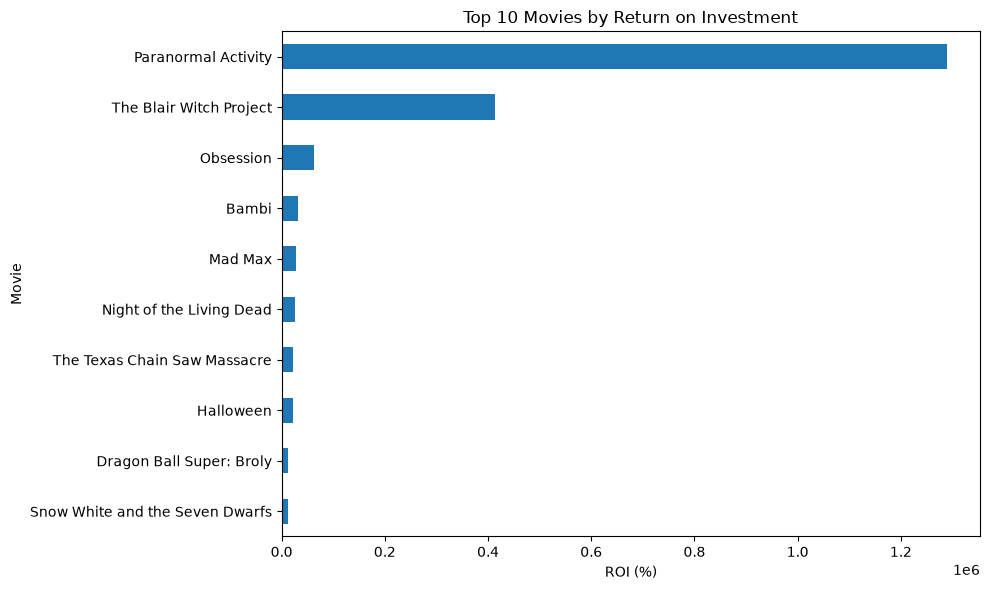

In [186]:
top_roi_sorted = top_roi_display.sort_values("ROI")

top_roi_sorted.plot(
    x="title",
    y="ROI",
    kind="barh",
    title="Top 10 Movies by Return on Investment",
    xlabel="ROI (%)",
    ylabel="Movie",
    legend=False,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [187]:
top_release_years = movies_per_year.sort_values(
    ascending=False
).head(10)

print("Top 10 years by number of movie releases:")
print(top_release_years)

Top 10 years by number of movie releases:
release_year
2016    121
2013    110
2017    109
2014    105
2018    102
2019    100
2015     97
2011     97
2010     90
2009     85
Name: count, dtype: int64


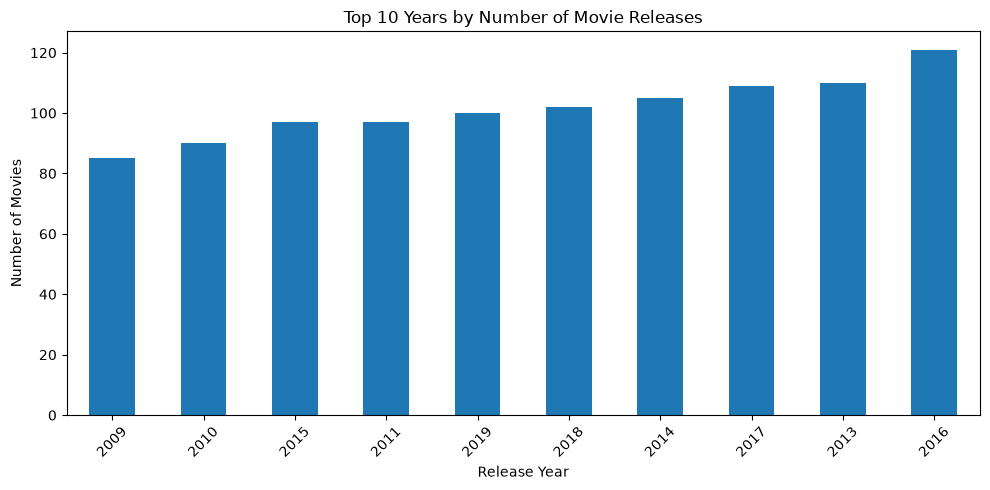

In [188]:
top_release_years_sorted = top_release_years.sort_values()

top_release_years_sorted.plot(
    kind="bar",
    title="Top 10 Years by Number of Movie Releases",
    xlabel="Release Year",
    ylabel="Number of Movies",
    figsize=(10, 5)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [189]:
print("Top 10 movie genres by number of appearances:")

print(genre_counts.head(10))

Top 10 movie genres by number of appearances:
genre_name
Drama              937
Action             808
Comedy             762
Adventure          674
Thriller           673
Science Fiction    463
Fantasy            396
Crime              387
Romance            349
Family             344
Name: count, dtype: int64


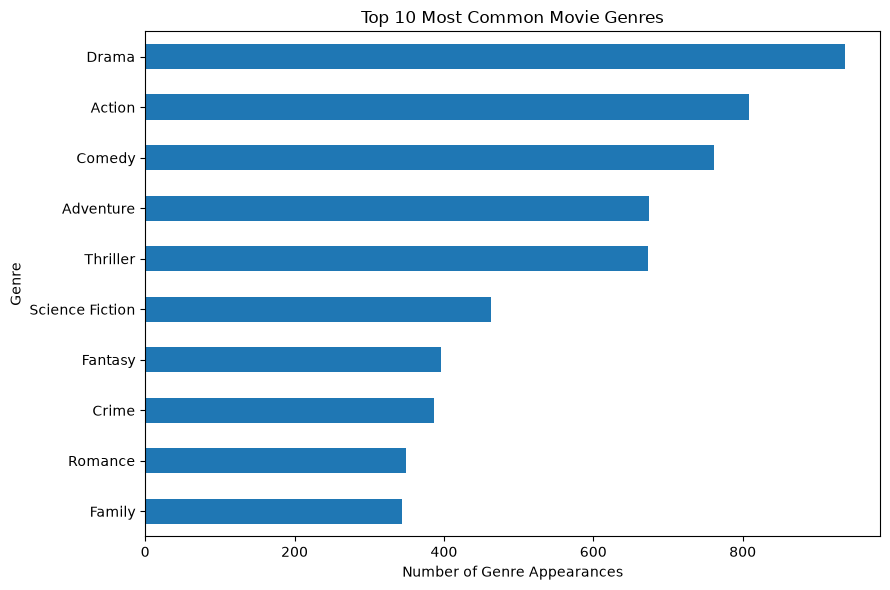

In [190]:
genre_counts.head(10).sort_values().plot(
    kind="barh",
    title="Top 10 Most Common Movie Genres",
    xlabel="Number of Genre Appearances",
    ylabel="Genre",
    figsize=(9, 6)
)

plt.tight_layout()
plt.show()

In [191]:
print("Columns in genre_ratings:")
print(genre_ratings.columns.tolist())

Columns in genre_ratings:
['movie_id', 'genre_id', 'genre_name', 'vote_average']


In [192]:
genre_average_ratings = (
    genre_ratings.groupby("genre_name")["vote_average"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 genres by average movie rating:")

print(genre_average_ratings.head(10).round(2))

Top 10 genres by average movie rating:
genre_name
War            7.36
History        7.34
Music          7.32
Documentary    7.31
Drama          7.25
Animation      7.20
Western        7.13
Romance        7.03
TV Movie       7.01
Crime          7.01
Name: vote_average, dtype: float64


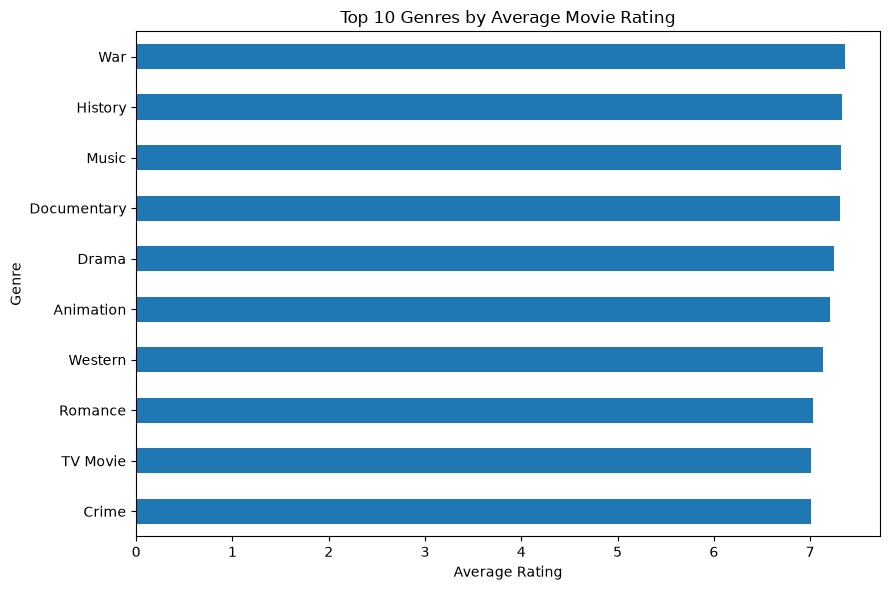

In [193]:
genre_average_ratings.head(10).sort_values().plot(
    kind="barh",
    title="Top 10 Genres by Average Movie Rating",
    xlabel="Average Rating",
    ylabel="Genre",
    figsize=(9, 6)
)

plt.tight_layout()
plt.show()

In [194]:
print(cast.columns.tolist())

['cast_row_id', 'movie_id', 'person_id', 'actor_name', 'character_name', 'cast_order']


In [195]:
top_actors = cast["actor_name"].value_counts().head(10)

print("Top 10 actors by number of cast appearances:")
print(top_actors)

Top 10 actors by number of cast appearances:
actor_name
Samuel L. Jackson     39
Brad Pitt             38
Robert De Niro        38
Johnny Depp           37
Tom Hanks             33
Scarlett Johansson    32
Willem Dafoe          32
Mark Wahlberg         32
Morgan Freeman        31
Tom Cruise            31
Name: count, dtype: int64


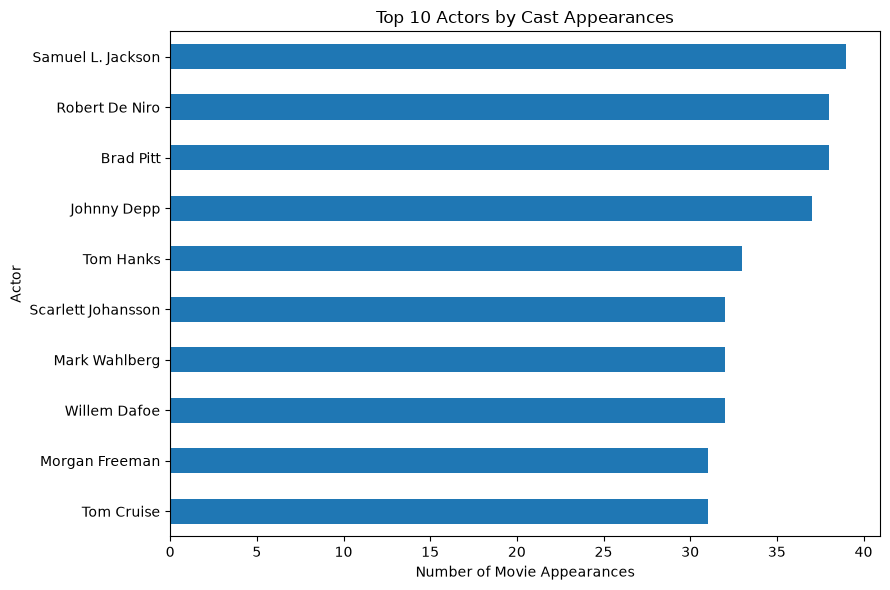

In [196]:
top_actors.sort_values().plot(
    kind="barh",
    title="Top 10 Actors by Cast Appearances",
    xlabel="Number of Movie Appearances",
    ylabel="Actor",
    figsize=(9, 6)
)

plt.tight_layout()
plt.show()

In [197]:
crew = pd.read_csv("../data/crew_cleaned.csv")

print("Crew dataset columns:")
print(crew.columns.tolist())

Crew dataset columns:
['crew_row_id', 'movie_id', 'person_id', 'person_name', 'job', 'department']


In [198]:
directors = crew[
    crew["job"].str.strip().str.lower() == "director"
]

top_directors = (
    directors.groupby("person_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 directors by number of movies:")
print(top_directors)

Top 10 directors by number of movies:
person_name
Steven Spielberg      27
Ridley Scott          19
Tim Burton            19
Martin Scorsese       16
Robert Zemeckis       15
Michael Bay           15
Clint Eastwood        14
Robert Rodriguez      13
M. Night Shyamalan    13
Antoine Fuqua         12
Name: movie_id, dtype: int64


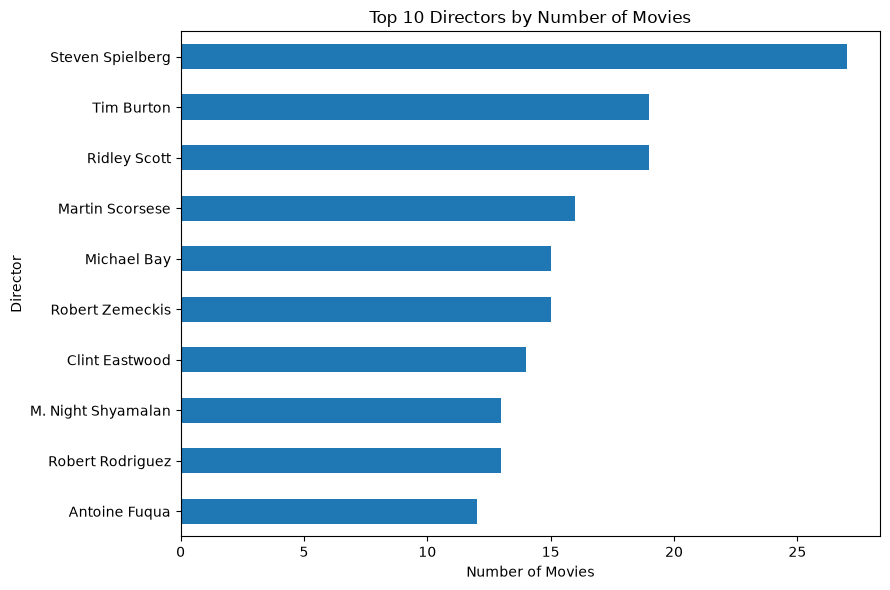

In [199]:
top_directors.sort_values().plot(
    kind="barh",
    title="Top 10 Directors by Number of Movies",
    xlabel="Number of Movies",
    ylabel="Director",
    figsize=(9, 6)
)

plt.tight_layout()
plt.show()

In [200]:
keywords = pd.read_csv("../data/movie_keywords_cleaned.csv")

print("Keywords dataset columns:")
print(keywords.columns.tolist())

Keywords dataset columns:
['movie_id', 'keyword_id', 'keyword_name']


In [201]:
top_keywords = (
    keywords.groupby("keyword_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 most frequent movie keywords:")
print(top_keywords)

Top 10 most frequent movie keywords:
keyword_name
based on novel or book    449
sequel                    416
duringcreditsstinger      296
aftercreditsstinger       242
murder                    176
based on true story       166
new york city             161
villain                   160
3d animation              155
based on comic            154
Name: movie_id, dtype: int64


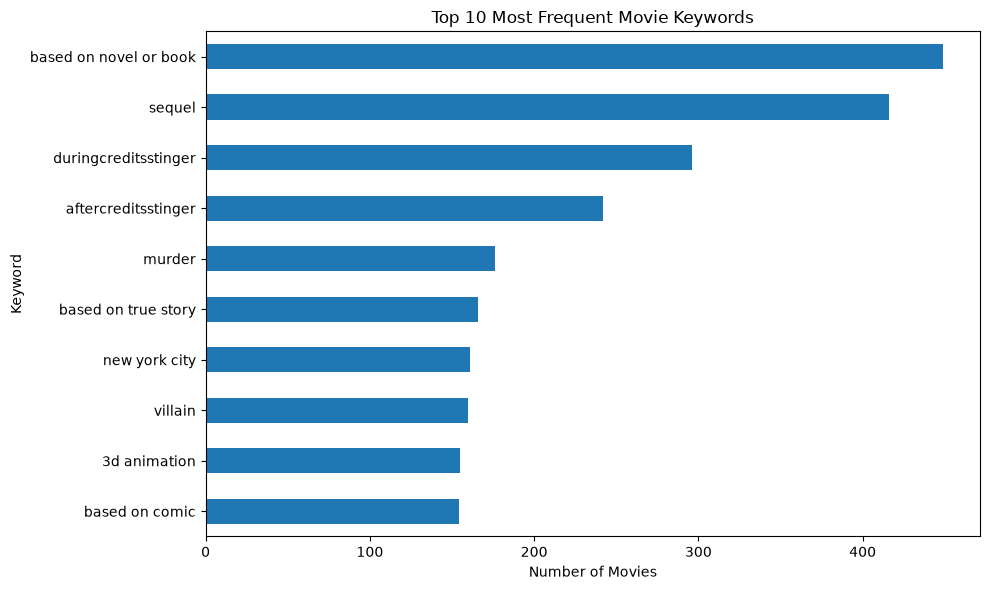

In [202]:
top_keywords.sort_values().plot(
    kind="barh",
    title="Top 10 Most Frequent Movie Keywords",
    xlabel="Number of Movies",
    ylabel="Keyword",
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [203]:
print("Shortest movie:", movies["runtime"].min(), "minutes")
print("Longest movie:", movies["runtime"].max(), "minutes")
print("Average movie duration:", round(movies["runtime"].mean(), 2), "minutes")

Shortest movie: 45 minutes
Longest movie: 242 minutes
Average movie duration: 114.41 minutes


In [204]:
long_movies = (
    movies[["title", "runtime"]]
    .dropna(subset=["runtime"])
    .sort_values("runtime", ascending=False)
    .head(10)
)

print("Top 10 longest movies:")
print(long_movies.to_string(index=False))

Top 10 longest movies:
                                        title  runtime
                 Zack Snyder's Justice League      242
                           Gone with the Wind      238
                  Once Upon a Time in America      229
                           Lawrence of Arabia      228
                                      Ben-Hur      212
                                 The Irishman      209
                                Seven Samurai      207
                   Killers of the Flower Moon      206
                        The Godfather Part II      202
The Lord of the Rings: The Return of the King      201


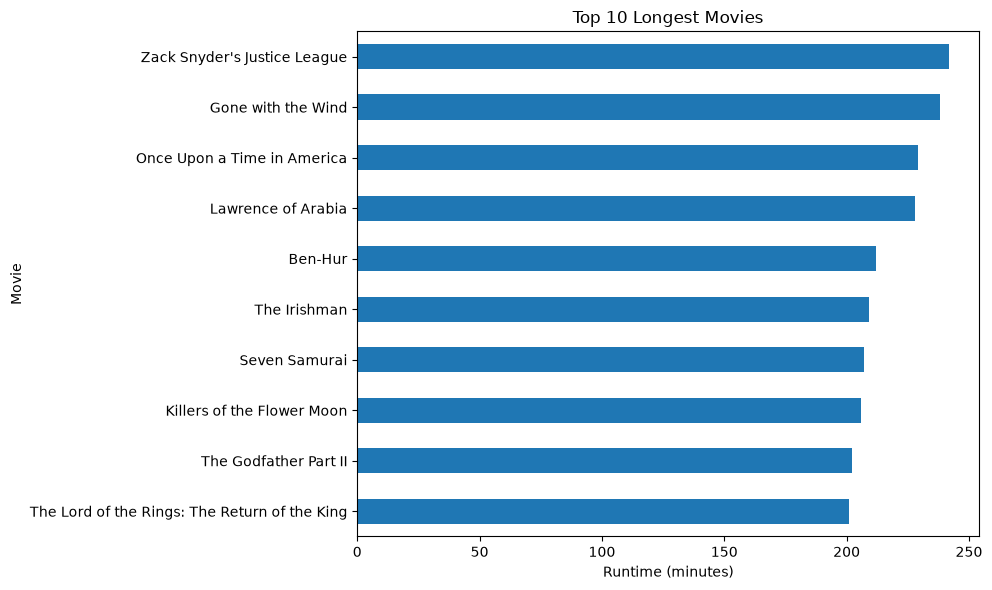

In [205]:
long_movies_sorted = long_movies.sort_values("runtime")

long_movies_sorted.plot(
    kind="barh",
    x="title",
    y="runtime",
    title="Top 10 Longest Movies",
    xlabel="Runtime (minutes)",
    ylabel="Movie",
    figsize=(10, 6),
    legend=False
)

plt.tight_layout()
plt.show()

In [206]:
print("Movies loaded:", len(movies))
print("Zero budgets:", (movies["budget"] == 0).sum())
print("Zero revenues:", (movies["revenue"] == 0).sum())
print("Missing budgets:", movies["budget"].isna().sum())
print("Missing revenues:", movies["revenue"].isna().sum())

Movies loaded: 2503
Zero budgets: 90
Zero revenues: 102
Missing budgets: 0
Missing revenues: 0


In [207]:
print("Unknown budgets for financial analysis:",
      financial_movies["budget"].isna().sum())

print("Unknown revenues for financial analysis:",
      financial_movies["revenue"].isna().sum())

Unknown budgets for financial analysis: 90
Unknown revenues for financial analysis: 102


## Data Cleaning Summary

The raw TMDB data was inspected and prepared for analysis across six related datasets.

Key cleaning and validation steps included:

- Loaded and inspected all six raw CSV datasets.
- Identified and removed duplicate records.
- Handled missing character names in the cast dataset.
- Preserved unknown financial values appropriately for financial analysis.
- Confirmed that `movie_id` is unique in the movies table.
- Validated relationships between movies, genres, cast, crew and keywords.
- Confirmed that no orphaned movie or genre references exist in the cleaned relational data.
- Prepared the cleaned datasets for storage in the SQLite relational database and subsequent SQL, Pandas and visual analysis.

After duplicate removal, the cleaned dataset contains 2,503 unique movies.